 # 02 — Repository-level analysis of review behaviour

## Research Objective

Investigate whether review oversight changes over a repository's history of
working with AI coding agents, and whether these changes differ between
agent-authored and human-authored pull requests.

## Research Questions

**RQ1 — Review Coverage**

How does formal review coverage of agent-authored pull requests change from the
early to the late stages of a repository's agentic history, compared with
human-authored pull requests in the same repositories?

**RQ2 — Approval Behaviour**

Among formally reviewed pull requests, how does approval behaviour change from
the early to the late stages of a repository's agentic history, and does that
change differ between agent-authored and human-authored pull requests?

## Metrics

- Review Coverage = PRs receiving at least one formal review / total PRs
- Approval Rate = approved formal review events / total formal review events

------------------------------------------------------------------------------------------------------------

## Setup and data loading

We first load the required libraries and define the project folders. The analysis uses a fixed AIDev revision so that the same data can be reproduced later.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

ROOT = Path.cwd()

if not (ROOT / "README.md").exists():
    if (ROOT.parent / "README.md").exists():
        ROOT = ROOT.parent

DATA_DIR = ROOT / "data"
FIGURE_DIR = ROOT / "figures"

DATA_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

print("Project root: ", ROOT)
print("Data directory: ", DATA_DIR)
print("Figure directory:", FIGURE_DIR)

Project root:  /Users/raselchowdhury/Desktop/LOG6307E/AI_Teammates_in_SE3
Data directory:  /Users/raselchowdhury/Desktop/LOG6307E/AI_Teammates_in_SE3/data
Figure directory: /Users/raselchowdhury/Desktop/LOG6307E/AI_Teammates_in_SE3/figures


In [3]:
REVISION = "68ed5f4b"
BASE = f"hf://datasets/hao-li/AIDev@{REVISION}"

print("Loading AIDev revision:", REVISION)

agentic_df = pd.read_parquet(
    f"{BASE}/pull_request.parquet"
)

human_df = pd.read_parquet(
    f"{BASE}/human_pull_request.parquet"
)

reviews_df = pd.read_parquet(
    f"{BASE}/pr_reviews.parquet"
)

print("AIDev loaded successfully.")

print("Agentic PRs: ", agentic_df.shape)
print("Human PRs:   ", human_df.shape)
print("Reviews:     ", reviews_df.shape)

Loading AIDev revision: 68ed5f4b
AIDev loaded successfully.
Agentic PRs:  (33596, 14)
Human PRs:    (6618, 13)
Reviews:      (28875, 7)


In [4]:
HUMAN_REVIEWS_FILE = DATA_DIR / "human_pr_reviews.jsonl"

if not HUMAN_REVIEWS_FILE.exists():
    raise FileNotFoundError(
        f"Missing file: {HUMAN_REVIEWS_FILE}"
    )

human_review_summary = pd.read_json(
    HUMAN_REVIEWS_FILE,
    lines=True
)

print("Collected Human PR records: ", len(human_review_summary))

print("Columns: ")
print(human_review_summary.columns.tolist())

display(human_review_summary.head())

Collected Human PR records:  6424
Columns: 
['pr_id', 'repo', 'number', 'n_reviews', 'n_comments', 'reviewers', 'review_states', 'commenters']


,pr_id,repo,number,n_reviews,n_comments,reviewers,review_states,commenters
0,2336888723,getsentry/sentry,85268,4,1,"[ameliahsu, natemoo-re]","[COMMENTED, COMMENTED, COMMENTED, APPROVED]",[codecov[bot]]
1,2447123365,getsentry/sentry,89131,1,3,[michellewzhang],[APPROVED],"[codecov[bot], gggritso, ryan953]"
2,2438086945,getsentry/sentry,88748,2,0,[GabeVillalobos],"[COMMENTED, APPROVED]",[]
3,2265431531,getsentry/sentry,83085,1,0,[obostjancic],[APPROVED],[]
4,2332333882,getsentry/sentry,85102,1,1,[wedamija],[APPROVED],[codecov[bot]]


## Data validation

Before starting the analysis, we check for duplicate PRs, missing review data, and the agents represented in the dataset.

In [5]:
print("Agentic duplicate PR IDs: ")
print(agentic_df["id"].duplicated().sum())

print("Human duplicate PR IDs: ")
print(human_df["id"].duplicated().sum())

print("Collected Human duplicate PR IDs: ")
print(human_review_summary["pr_id"].duplicated().sum())

print("Human PRs missing from collected review data: ")

missing_human_collections = (
    len(human_df)
    - human_df["id"].isin(
        human_review_summary["pr_id"]
    ).sum()
)

print(missing_human_collections)

print("Agent identities: ")
print(agentic_df["agent"].value_counts())

Agentic duplicate PR IDs: 
0
Human duplicate PR IDs: 
0
Collected Human duplicate PR IDs: 
0
Human PRs missing from collected review data: 
194
Agent identities: 
agent
OpenAI_Codex    21799
Copilot          4970
Devin            4827
Cursor           1541
Claude_Code       459
Name: count, dtype: int64


In [6]:
for df in [agentic_df, human_df]:
    for col in ["created_at", "closed_at", "merged_at"]:
        if col in df.columns:
            df[col] = pd.to_datetime(
                df[col],
                utc=True,
                errors="coerce"
            )

print("Agentic date range: ")
print(
    agentic_df["created_at"].min(),
    "=>",
    agentic_df["created_at"].max()
)

print("Human date range: ")
print(
    human_df["created_at"].min(),
    "=>",
    human_df["created_at"].max()
)

Agentic date range: 
2024-12-24 00:23:09+00:00 => 2025-07-30 19:36:13+00:00
Human date range: 
2025-01-01 00:22:59+00:00 => 2025-06-28 19:44:33+00:00


## Defining early and late repository history

For each repository, agent-authored PRs are ordered by creation date. We split this history into an early and a late period and use the same time window for human-authored PRs.

In [7]:
boundaries = []

for repo_url, group in agentic_df.groupby("repo_url"):

    g = (
        group
        .dropna(subset=["created_at"])
        .sort_values("created_at")
        .reset_index(drop=True)
    )

    n = len(g)

    if n < 2:
        continue

    split = n // 2

    early_last = g.loc[split - 1, "created_at"]
    late_first = g.loc[split, "created_at"]
    midpoint = early_last + (late_first - early_last) / 2

    boundaries.append({
        "repo_url": repo_url,
        "agentic_first": g["created_at"].min(),
        "agentic_last": g["created_at"].max(),
        "agentic_midpoint": midpoint,
        "n_agentic_total": n,
    })

boundaries = pd.DataFrame(boundaries)

print("Repositories with an agentic history: ", len(boundaries))

display(boundaries.head())

Repositories with an agentic history:  1574


,repo_url,agentic_first,agentic_last,agentic_midpoint,n_agentic_total
0,https://api.github.com/repos/0x2E/fusion,2025-07-27 15:04:30+00:00,2025-07-27 15:07:17+00:00,2025-07-27 15:05:53.500000+00:00,2
1,https://api.github.com/repos/0x4D31/finch,2025-07-27 22:55:49+00:00,2025-07-30 00:17:40+00:00,2025-07-28 23:36:44.500000+00:00,2
2,https://api.github.com/repos/0x4D31/galah,2025-05-17 09:05:23+00:00,2025-07-24 03:07:45+00:00,2025-05-17 21:09:47+00:00,16
3,https://api.github.com/repos/0x80/isolate-package,2025-07-13 19:36:03+00:00,2025-07-13 22:03:19+00:00,2025-07-13 20:13:29.500000+00:00,5
4,https://api.github.com/repos/0xfurai/peekaping,2025-07-13 19:07:57+00:00,2025-07-19 13:52:45+00:00,2025-07-14 13:03:45+00:00,8


In [8]:
agentic_window = agentic_df.merge(
    boundaries,
    on="repo_url",
    how="inner"
)

human_window = human_df.merge(
    boundaries,
    on="repo_url",
    how="inner"
)

human_window = human_window[
    (human_window["created_at"] >= human_window["agentic_first"]) &
    (human_window["created_at"] <= human_window["agentic_last"])
].copy()

print("Agentic PRs in window: ", len(agentic_window))
print("Human PRs in window:   ", len(human_window))

Agentic PRs in window:  32363
Human PRs in window:    2784


## Building the study sample

We keep repositories with enough agent-authored and human-authored PRs to make the comparison meaningful. Repositories must also contain both PR origins in both the early and late periods.

In [9]:
MIN_PRS_PER_ORIGIN = 10

agentic_counts = (
    agentic_window
    .groupby("repo_url")
    .size()
    .rename("n_agentic")
)

human_counts = (
    human_window
    .groupby("repo_url")
    .size()
    .rename("n_human")
)

repo_counts = pd.concat(
    [agentic_counts, human_counts],
    axis=1
).fillna(0)

eligible_repos = repo_counts[
    (repo_counts["n_agentic"] >= MIN_PRS_PER_ORIGIN) &
    (repo_counts["n_human"] >= MIN_PRS_PER_ORIGIN)
].copy()

print("Eligible repositories: ", len(eligible_repos))

print("Summary of PR counts in eligible repositories: ")
display(eligible_repos.describe().round(1))

Eligible repositories:  54
Summary of PR counts in eligible repositories: 


,n_agentic,n_human
count,54.0,54.0
mean,85.1,41.9
std,76.2,55.8
min,12.0,10.0
25%,31.8,13.0
50%,55.5,17.0
75%,109.8,39.0
max,358.0,293.0


In [10]:
kept_repos = set(eligible_repos.index)

agentic_sample = agentic_window[
    agentic_window["repo_url"].isin(kept_repos)
].copy()

human_sample = human_window[
    human_window["repo_url"].isin(kept_repos)
].copy()

agentic_sample["origin"] = "Agentic"
human_sample["origin"] = "Human"

common_columns = sorted(
    set(agentic_sample.columns)
    & set(human_sample.columns)
)

prs = pd.concat(
    [
        agentic_sample[common_columns],
        human_sample[common_columns],
    ],
    ignore_index=True
)

print("Combined study sample: ", prs.shape)

print("PRs by origin: ")
print(prs["origin"].value_counts())

print("Repositories: ")
print(prs["repo_url"].nunique())

Combined study sample:  (6861, 18)
PRs by origin: 
origin
Agentic    4597
Human      2264
Name: count, dtype: int64
Repositories: 
54


In [11]:
prs["period"] = np.where(
    prs["created_at"] < prs["agentic_midpoint"],
    "Early",
    "Late"
)

period_counts = (
    prs
    .groupby(["repo_url", "origin", "period"])
    .size()
    .unstack(["origin", "period"])
)

pairable_mask = period_counts.notna().all(axis=1)

pairable_repos = set(
    period_counts.index[pairable_mask]
)

prs = prs[
    prs["repo_url"].isin(pairable_repos)
].copy()

print(
    "Repositories with both origins in both periods: ",
    len(pairable_repos)
)

print("PR distribution: ")
print(
    prs.groupby(["origin", "period"]).size()
)

Repositories with both origins in both periods:  47
PR distribution: 
origin   period
Agentic  Early     2147
         Late      2172
Human    Early     1237
         Late       931
dtype: int64


## Inspecting the review data

The review table contains both human and automated reviewers. Since the research questions focus on human oversight, we first inspect reviewer types and review states before calculating the final metrics.

In [12]:
print("Review table columns: ")
print(reviews_df.columns.tolist())

print("Review states: ")
print(reviews_df["state"].value_counts(dropna=False))

if "user_type" in reviews_df.columns:
    print("Reviewer types: ")
    print(reviews_df["user_type"].value_counts(dropna=False))

print("Example reviews: ")
display(reviews_df.head(10))

Review table columns: 
['id', 'pr_id', 'user', 'user_type', 'state', 'submitted_at', 'body']
Review states: 
state
COMMENTED            20431
APPROVED              6499
CHANGES_REQUESTED     1604
DISMISSED              341
Name: count, dtype: int64
Reviewer types: 
user_type
User    16895
Bot     11979
NaN         1
Name: count, dtype: int64
Example reviews: 


,id,pr_id,user,user_type,state,submitted_at,body
0,2885691382,3107321792,coderabbitai[bot],Bot,COMMENTED,2025-06-01T14:22:22Z,**Actionable comments posted: 2**\n\n<details>\n<summary>🔭 Outside diff range comments (1)</summary><blockquote>\n\n...
1,2885712797,3107321792,coderabbitai[bot],Bot,COMMENTED,2025-06-01T14:37:45Z,**Actionable comments posted: 1**\n\n<details>\n<summary>📜 Review details</summary>\n\n**Configuration used: CodeRab...
2,3059587397,3234660269,Fank,User,COMMENTED,2025-07-27T15:06:40Z,NaN
3,3059589121,3234660269,benfdking,User,COMMENTED,2025-07-27T15:12:52Z,NaN
4,2813254905,3037457814,wilsonccccc,User,APPROVED,2025-05-03T15:34:42Z,NaN
5,2679908484,2915198291,ellipsis-dev[bot],Bot,COMMENTED,2025-03-12T21:24:55Z,:+1: Looks good to me! Reviewed everything up to dd367037bf140f689751ae514b9bc27f43bd94af in <ellipsistime>1 minute ...
6,3011938086,3223924413,davinchia,User,COMMENTED,2025-07-11T20:48:38Z,NaN
7,3034262238,3223924413,aaronsteers,User,APPROVED,2025-07-18T17:11:06Z,NaN
8,2866389127,3088611576,copilot-pull-request-reviewer[bot],Bot,COMMENTED,2025-05-24T17:14:22Z,## Pull Request Overview\n\nImplements dot‐notation access for workflow outputs and refactors configuration loading ...
9,2866393218,3088611576,parruda,User,APPROVED,2025-05-24T17:34:15Z,NaN


In [13]:
def is_bot_login(login):
    if not isinstance(login, str):
        return False

    login_lower = login.lower()

    return (
        login_lower.endswith("[bot]")
        or login_lower.endswith("-bot")
        or login_lower.endswith("_bot")
    )


human_review_summary["n_unique_reviewers"] = (
    human_review_summary["reviewers"]
    .apply(
        lambda x: len(x)
        if isinstance(x, (list, tuple, np.ndarray))
        else 0
    )
)

human_review_summary["n_bot_named_reviewers"] = (
    human_review_summary["reviewers"]
    .apply(
        lambda x: sum(
            is_bot_login(login)
            for login in x
        )
        if isinstance(x, (list, tuple, np.ndarray))
        else 0
    )
)

human_review_summary["n_review_states"] = (
    human_review_summary["review_states"]
    .apply(
        lambda x: len(x)
        if isinstance(x, (list, tuple, np.ndarray))
        else 0
    )
)

print("Human PRs with at least one review: ")
print((human_review_summary["n_reviews"] > 0).sum())

print("\nHuman PRs with at least one bot-looking reviewer: ")
print((human_review_summary["n_bot_named_reviewers"] > 0).sum())

print("Do n_reviews and number of stored review states match? ")
print(
    (
        human_review_summary["n_reviews"]
        == human_review_summary["n_review_states"]
    ).value_counts()
)

print("Do n_reviews and number of UNIQUE reviewers match? ")
print(
    (
        human_review_summary["n_reviews"]
        == human_review_summary["n_unique_reviewers"]
    ).value_counts()
)

display(
    human_review_summary[
        [
            "pr_id",
            "n_reviews",
            "n_unique_reviewers",
            "n_bot_named_reviewers",
            "reviewers",
            "review_states",
        ]
    ].head(10)
)

Human PRs with at least one review: 
3840

Human PRs with at least one bot-looking reviewer: 
1201
Do n_reviews and number of stored review states match? 
True    6424
Name: count, dtype: int64
Do n_reviews and number of UNIQUE reviewers match? 
True     5208
False    1216
Name: count, dtype: int64


,pr_id,n_reviews,n_unique_reviewers,n_bot_named_reviewers,reviewers,review_states
0,2336888723,4,2,0,"[ameliahsu, natemoo-re]","[COMMENTED, COMMENTED, COMMENTED, APPROVED]"
1,2447123365,1,1,0,[michellewzhang],[APPROVED]
2,2438086945,2,1,0,[GabeVillalobos],"[COMMENTED, APPROVED]"
3,2265431531,1,1,0,[obostjancic],[APPROVED]
4,2332333882,1,1,0,[wedamija],[APPROVED]
5,2520698034,0,0,0,[],[]
6,2260964437,1,1,0,[davidmigloz],[APPROVED]
7,2282291240,1,1,0,[pavelsavara],[APPROVED]
8,2400016065,2,2,0,"[bhancockio, lorenzejay]","[APPROVED, APPROVED]"
9,2368501003,0,0,0,[],[]


### Collecting detailed reviews for human-authored PRs

The first human-PR review file does not contain enough information to reliably match each review state to a human or bot reviewer. We therefore retrieve the detailed review events from GitHub for the final sample.

In [18]:
OUT_EVENTS = DATA_DIR / "human_pr_review_events.jsonl"

if not OUT_EVENTS.exists():
    raise FileNotFoundError(
        f"Missing collected review file: {OUT_EVENTS}"
    )

print("Using existing collected Human PR review data.")
print("File:", OUT_EVENTS)

Using existing collected Human PR review data.
File: /Users/raselchowdhury/Desktop/LOG6307E/AI_Teammates_in_SE3/data/human_pr_review_events.jsonl


In [19]:
HUMAN_EVENTS_FILE = DATA_DIR / "human_pr_review_events.jsonl"

human_events_raw = pd.read_json(
    HUMAN_EVENTS_FILE,
    lines=True
)

print("Collected Human PR records:", len(human_events_raw))

print(
    "Unique Human PR IDs:",
    human_events_raw["pr_id"].nunique()
)

print(
    "Duplicate PR records:",
    human_events_raw["pr_id"].duplicated().sum()
)

expected_human_ids = set(
    prs.loc[
        prs["origin"] == "Human",
        "id"
    ]
)

collected_human_ids = set(
    human_events_raw["pr_id"]
)

missing_human_ids = (
    expected_human_ids
    - collected_human_ids
)

print(
    "Missing detailed Human PR review records:",
    len(missing_human_ids)
)

missing_human_repos = set(
    prs.loc[
        (prs["origin"] == "Human")
        & (prs["id"].isin(missing_human_ids)),
        "repo_url",
    ]
)

print("\nRepositories affected by missing Human review data:")
print(len(missing_human_repos))

for repo in sorted(missing_human_repos):
    print(" -", repo)

prs = prs[
    ~prs["repo_url"].isin(missing_human_repos)
].copy()

retained_human_ids = set(
    prs.loc[
        prs["origin"] == "Human",
        "id"
    ]
)

remaining_missing_human_ids = (
    retained_human_ids
    - collected_human_ids
)

print("\nRepositories after symmetric exclusion:")
print(prs["repo_url"].nunique())

print("PRs after symmetric exclusion:")
print(len(prs))

print("Remaining Human PRs without detailed review data:")
print(len(remaining_missing_human_ids))

assert len(remaining_missing_human_ids) == 0, (
    "Some retained Human PRs still lack detailed review data."
)

Collected Human PR records: 2034
Unique Human PR IDs: 2034
Duplicate PR records: 0
Missing detailed Human PR review records: 134

Repositories affected by missing Human review data:
1
 - https://api.github.com/repos/antiwork/flexile

Repositories after symmetric exclusion:
46
PRs after symmetric exclusion:
6147
Remaining Human PRs without detailed review data:
0


In [20]:
human_review_events = (
    human_events_raw[["pr_id", "reviews"]]
    .explode("reviews")
    .dropna(subset=["reviews"])
    .reset_index(drop=True)
)

review_details = pd.json_normalize(
    human_review_events["reviews"]
)

human_review_events = pd.concat(
    [
        human_review_events[["pr_id"]].reset_index(drop=True),
        review_details.reset_index(drop=True),
    ],
    axis=1
)

print("Total Human review events: ", len(human_review_events))

print("Reviewer types: ")
print(
    human_review_events["reviewer_type"]
    .value_counts(dropna=False)
)

print("Review states: ")
print(
    human_review_events["state"]
    .value_counts(dropna=False)
)

display(human_review_events.head(10))

Total Human review events:  3635
Reviewer types: 
reviewer_type
User    2734
Bot      900
NaN        1
Name: count, dtype: int64
Review states: 
state
COMMENTED            2334
APPROVED             1105
CHANGES_REQUESTED     103
DISMISSED              93
Name: count, dtype: int64


,pr_id,review_id,reviewer,reviewer_type,state,submitted_at
0,2336888723,2618604424,ameliahsu,User,COMMENTED,2025-02-14T19:06:37Z
1,2336888723,2618606142,ameliahsu,User,COMMENTED,2025-02-14T19:07:42Z
2,2336888723,2625030950,natemoo-re,User,COMMENTED,2025-02-18T21:23:48Z
3,2336888723,2625204648,natemoo-re,User,APPROVED,2025-02-18T22:40:44Z
4,2447123365,2751626124,michellewzhang,User,APPROVED,2025-04-08T23:43:49Z
5,2438086945,2741254406,GabeVillalobos,User,COMMENTED,2025-04-03T21:53:18Z
6,2438086945,2741255232,GabeVillalobos,User,APPROVED,2025-04-03T21:53:24Z
7,2332333882,2613284765,wedamija,User,APPROVED,2025-02-12T21:48:36Z
8,2486573779,2800275862,leeandher,User,COMMENTED,2025-04-28T18:25:23Z
9,2486573779,2800458358,armenzg,User,APPROVED,2025-04-28T19:19:38Z


In [21]:
agentic_sample_ids = set(
    prs.loc[
        prs["origin"] == "Agentic",
        "id"
    ]
)

human_sample_ids = set(
    prs.loc[
        prs["origin"] == "Human",
        "id"
    ]
)

agentic_human_reviews = reviews_df[
    (reviews_df["user_type"] == "User") &
    (reviews_df["pr_id"].isin(agentic_sample_ids))
].copy()

agentic_human_reviews["state"] = (
    agentic_human_reviews["state"]
    .astype(str)
    .str.upper()
)

agentic_human_reviews["submitted_at"] = pd.to_datetime(
    agentic_human_reviews["submitted_at"],
    utc=True,
    errors="coerce"
)

human_human_reviews = human_review_events[
    (human_review_events["reviewer_type"] == "User") &
    (human_review_events["pr_id"].isin(human_sample_ids))
].copy()

human_human_reviews["state"] = (
    human_human_reviews["state"]
    .astype(str)
    .str.upper()
)

human_human_reviews["submitted_at"] = pd.to_datetime(
    human_human_reviews["submitted_at"],
    utc=True,
    errors="coerce"
)

print("Human review events on Agentic PRs: ")
print(len(agentic_human_reviews))

print("Human review events on Human PRs: ")
print(len(human_human_reviews))

print("Agentic-PR review states: ")
print(
    agentic_human_reviews["state"]
    .value_counts()
)

print("Human-PR review states: ")
print(
    human_human_reviews["state"]
    .value_counts()
)

Human review events on Agentic PRs: 
3922
Human review events on Human PRs: 
2734
Agentic-PR review states: 
state
COMMENTED            2045
APPROVED             1628
CHANGES_REQUESTED     152
DISMISSED              97
Name: count, dtype: int64
Human-PR review states: 
state
COMMENTED            1438
APPROVED             1100
CHANGES_REQUESTED     103
DISMISSED              93
Name: count, dtype: int64


## PR-level review measures

The human review events are summarized at the pull-request level. For each PR, we record whether it received a human review, the number of human reviews, and the number of approvals.

In [22]:
agentic_review_summary = (
    agentic_human_reviews
    .groupby("pr_id")
    .agg(
        n_human_reviews=("id", "size"),
        n_human_approvals=(
            "state",
            lambda s: (s == "APPROVED").sum()
        ),
    )
    .reset_index()
)

human_review_event_summary = (
    human_human_reviews
    .groupby("pr_id")
    .agg(
        n_human_reviews=("review_id", "size"),
        n_human_approvals=(
            "state",
            lambda s: (s == "APPROVED").sum()
        ),
    )
    .reset_index()
)

prs["review_data_available"] = False
prs["n_human_reviews"] = np.nan
prs["n_human_approvals"] = np.nan

agentic_mask = (
    prs["origin"] == "Agentic"
)

agentic_reviews_map = (
    agentic_review_summary
    .set_index("pr_id")["n_human_reviews"]
)

agentic_approvals_map = (
    agentic_review_summary
    .set_index("pr_id")["n_human_approvals"]
)

prs.loc[
    agentic_mask,
    "n_human_reviews"
] = (
    prs.loc[agentic_mask, "id"]
    .map(agentic_reviews_map)
    .fillna(0)
)

prs.loc[
    agentic_mask,
    "n_human_approvals"
] = (
    prs.loc[agentic_mask, "id"]
    .map(agentic_approvals_map)
    .fillna(0)
)

prs.loc[
    agentic_mask,
    "review_data_available"
] = True

human_mask = (
    prs["origin"] == "Human"
)

human_reviews_map = (
    human_review_event_summary
    .set_index("pr_id")["n_human_reviews"]
)

human_approvals_map = (
    human_review_event_summary
    .set_index("pr_id")["n_human_approvals"]
)

collected_ids = set(
    human_events_raw["pr_id"]
)

prs.loc[
    human_mask,
    "review_data_available"
] = (
    prs.loc[human_mask, "id"]
    .isin(collected_ids)
)

available_human_mask = (
    human_mask
    & prs["review_data_available"]
)

prs.loc[
    available_human_mask,
    "n_human_reviews"
] = (
    prs.loc[
        available_human_mask,
        "id"
    ]
    .map(human_reviews_map)
    .fillna(0)
)

prs.loc[
    available_human_mask,
    "n_human_approvals"
] = (
    prs.loc[
        available_human_mask,
        "id"
    ]
    .map(human_approvals_map)
    .fillna(0)
)

prs["has_human_review"] = np.where(
    prs["review_data_available"],
    prs["n_human_reviews"] > 0,
    np.nan
)

prs["human_approval_rate"] = np.where(
    prs["n_human_reviews"] > 0,
    prs["n_human_approvals"]
    / prs["n_human_reviews"],
    np.nan
)

print("Review-data availability:")

availability_check = (
    prs
    .groupby("origin")["review_data_available"]
    .agg(["sum", "count"])
)

display(availability_check)

print("\nPRs receiving at least one human review:")

print(
    prs[
        prs["review_data_available"]
    ]
    .groupby("origin")["has_human_review"]
    .agg(["sum", "count"])
)

print("\nTotal human review events attached:")

print(
    prs
    .groupby("origin")["n_human_reviews"]
    .sum()
)

assert prs["review_data_available"].all(), (
    "The final study sample still contains PRs with unavailable review data."
)

print("\n✓ All retained PRs have review data.")

Review-data availability:


,sum,count
origin,,
Agentic,4113,4113
Human,2034,2034



PRs receiving at least one human review:
            sum  count
origin                
Agentic  1468.0   4113
Human    1020.0   2034

Total human review events attached:
origin
Agentic    3922.0
Human      2734.0
Name: n_human_reviews, dtype: float64

✓ All retained PRs have review data.


## RQ1 — Human review coverage

For RQ1, review coverage is calculated for each repository, PR origin, and period. Early and late values from the same repository are then compared using paired statistical tests.

In [23]:
coverage_input = prs[
    prs["review_data_available"] == True
].copy()

coverage = (
    coverage_input
    .groupby(
        ["repo_url", "origin", "period"]
    )
    .agg(
        n_prs=("id", "size"),
        n_reviewed=("has_human_review", "sum"),
    )
    .reset_index()
)

coverage["review_coverage"] = (
    coverage["n_reviewed"]
    / coverage["n_prs"]
)

print("Coverage rows: ", len(coverage))

print("Overall review coverage by origin and period: ")

overall_coverage = (
    coverage_input
    .groupby(["origin", "period"])
    .agg(
        n_prs=("id", "size"),
        n_reviewed=("has_human_review", "sum"),
    )
)

overall_coverage["review_coverage"] = (
    overall_coverage["n_reviewed"]
    / overall_coverage["n_prs"]
)

display(
    overall_coverage.round(4)
)

print("Median repository-level review coverage: ")

median_coverage = (
    coverage
    .groupby(["origin", "period"])
    ["review_coverage"]
    .median()
)

print(median_coverage.round(4))

Coverage rows:  184
Overall review coverage by origin and period: 


n_prs  n_reviewed  review_coverage
origin  period                                    
Agentic Early    2044       749.0           0.3664
        Late     2069       719.0           0.3475
Human   Early    1128       586.0           0.5195
        Late      906       434.0           0.4790

Median repository-level review coverage: 
origin   period
Agentic  Early     0.2247
         Late      0.2424
Human    Early     0.3594
         Late      0.5109
Name: review_coverage, dtype: float64


### RQ1 result

The paired tests do not show a statistically significant early-to-late change in human review coverage for either agent-authored or human-authored PRs. The difference between the two trajectories is also not statistically significant.

In [24]:
coverage_wide = (
    coverage
    .pivot(
        index="repo_url",
        columns=["origin", "period"],
        values="review_coverage"
    )
)

required_columns = [
    ("Agentic", "Early"),
    ("Agentic", "Late"),
    ("Human", "Early"),
    ("Human", "Late"),
]

coverage_paired = (
    coverage_wide[required_columns]
    .dropna()
    .copy()
)

coverage_paired.columns = [
    "Agentic_Early",
    "Agentic_Late",
    "Human_Early",
    "Human_Late",
]

coverage_paired["Agentic_Delta"] = (
    coverage_paired["Agentic_Late"]
    - coverage_paired["Agentic_Early"]
)

coverage_paired["Human_Delta"] = (
    coverage_paired["Human_Late"]
    - coverage_paired["Human_Early"]
)

print("Repositories with complete RQ1 pairs: ")
print(len(coverage_paired))

print("Median review coverage: ")

print(
    coverage_paired[
        [
            "Agentic_Early",
            "Agentic_Late",
            "Human_Early",
            "Human_Late",
        ]
    ]
    .median()
    .round(4)
)

print("Median Early ==> Late change: ")

print(
    coverage_paired[
        [
            "Agentic_Delta",
            "Human_Delta",
        ]
    ]
    .median()
    .round(4)
)

display(coverage_paired.head())

Repositories with complete RQ1 pairs: 
46
Median review coverage: 
Agentic_Early    0.2247
Agentic_Late     0.2424
Human_Early      0.3594
Human_Late       0.5109
dtype: float64
Median Early ==> Late change: 
Agentic_Delta   -0.0045
Human_Delta      0.0191
dtype: float64


,Agentic_Early,Agentic_Late,Human_Early,Human_Late,Agentic_Delta,Human_Delta
repo_url,,,,,,
https://api.github.com/repos/AgentOps-AI/agentops,0.200000,0.115385,0.34375,1.000000,-0.084615,0.656250
https://api.github.com/repos/EricLBuehler/mistral.rs,0.000000,0.076923,0.00000,0.375000,0.076923,0.375000
https://api.github.com/repos/GlareDB/glaredb,0.562500,0.632653,0.00000,0.000000,0.070153,0.000000
https://api.github.com/repos/Kanaries/graphic-walker,0.222222,0.000000,1.00000,0.700000,-0.222222,-0.300000
https://api.github.com/repos/OneKeyHQ/app-monorepo,0.142857,0.137931,0.85000,0.944444,-0.004926,0.094444


In [25]:
from scipy.stats import wilcoxon


def paired_wilcoxon(before, after, label):
    before = pd.Series(before, dtype=float)
    after = pd.Series(after, dtype=float)

    mask = before.notna() & after.notna()

    before = before[mask]
    after = after[mask]

    delta = after.to_numpy() - before.to_numpy()

    print("\n" + "=" * 60)
    print(label)
    print("=" * 60)

    print("Number of paired repositories: ", len(delta))
    print("Median Early: ", round(float(np.median(before)), 4))
    print("Median Late: ", round(float(np.median(after)), 4))
    print("Median Delta: ", round(float(np.median(delta)), 4))

    if np.allclose(delta, 0):
        print("All paired differences are zero.")
        return None

    result = wilcoxon(
        after,
        before,
        alternative="two-sided",
        zero_method="wilcox"
    )

    print("Wilcoxon statistic: ", round(float(result.statistic), 4))
    print("p-value: ", result.pvalue)

    return result

rq1_agentic_test = paired_wilcoxon(
    coverage_paired["Agentic_Early"],
    coverage_paired["Agentic_Late"],
    "Agentic PRs: Early vs Late review coverage"
)

rq1_human_test = paired_wilcoxon(
    coverage_paired["Human_Early"],
    coverage_paired["Human_Late"],
    "Human PRs: Early vs Late review coverage"
)

rq1_delta_test = paired_wilcoxon(
    coverage_paired["Human_Delta"],
    coverage_paired["Agentic_Delta"],
    "Difference in Early => Late change: Agentic vs Human"
)


Agentic PRs: Early vs Late review coverage
Number of paired repositories:  46
Median Early:  0.2247
Median Late:  0.2424
Median Delta:  -0.0045
Wilcoxon statistic:  382.5
p-value:  0.3882641249020635

Human PRs: Early vs Late review coverage
Number of paired repositories:  46
Median Early:  0.3594
Median Late:  0.5109
Median Delta:  0.0191
Wilcoxon statistic:  281.5
p-value:  0.1967715314606714

Difference in Early => Late change: Agentic vs Human
Number of paired repositories:  46
Median Early:  0.0191
Median Late:  -0.0045
Median Delta:  -0.0828
Wilcoxon statistic:  395.0
p-value:  0.16674917828607672


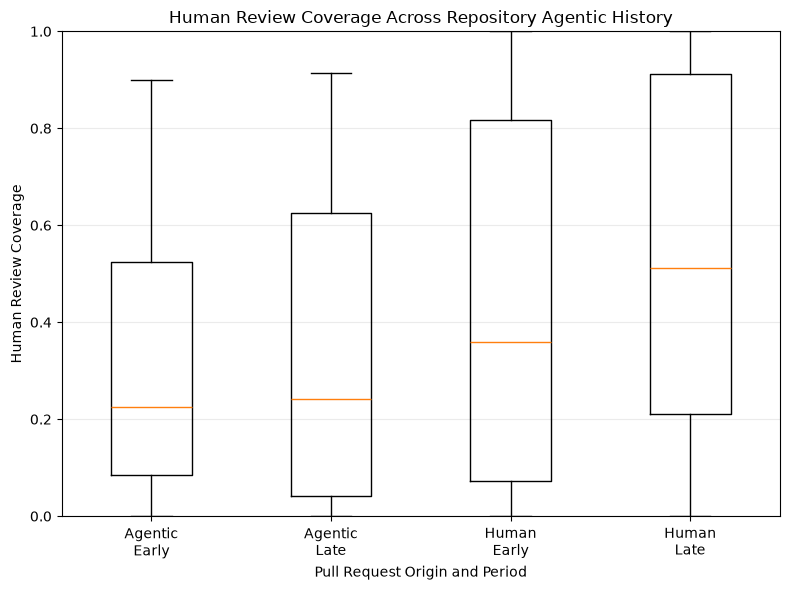

Saved figure to: 
/Users/raselchowdhury/Desktop/LOG6307E/AI_Teammates_in_SE3/figures/rq1_review_coverage.png


In [26]:
fig, ax = plt.subplots(figsize=(8, 6))

plot_data = [
    coverage_paired["Agentic_Early"],
    coverage_paired["Agentic_Late"],
    coverage_paired["Human_Early"],
    coverage_paired["Human_Late"],
]

labels = [
    "Agentic\nEarly",
    "Agentic\nLate",
    "Human\nEarly",
    "Human\nLate",
]

ax.boxplot(
    plot_data,
    tick_labels=labels,
    showfliers=False,
)

ax.set_ylabel("Human Review Coverage")
ax.set_xlabel("Pull Request Origin and Period")

ax.set_title(
    "Human Review Coverage Across Repository Agentic History"
)

ax.set_ylim(0, 1)

ax.grid(
    axis="y",
    alpha=0.25
)

fig.tight_layout()

rq1_figure_path = (
    FIGURE_DIR
    / "rq1_review_coverage.png"
)

fig.savefig(
    rq1_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Saved figure to: ")
print(rq1_figure_path)

## RQ2 — Human approval behaviour

For RQ2, we focus on human review events and calculate approval rates at the repository level. We also require a minimum number of reviews so that the results are not based on only one or two observations.

In [27]:
pr_lookup = prs[
    [
        "id",
        "repo_url",
        "origin",
        "period",
    ]
].copy()

pr_lookup = pr_lookup.rename(
    columns={"id": "pr_id"}
)

agentic_rq2 = (
    agentic_human_reviews[
        [
            "pr_id",
            "state",
            "submitted_at",
        ]
    ]
    .merge(
        pr_lookup,
        on="pr_id",
        how="inner",
    )
)


human_rq2 = (
    human_human_reviews[
        [
            "pr_id",
            "state",
            "submitted_at",
        ]
    ]
    .merge(
        pr_lookup,
        on="pr_id",
        how="inner",
    )
)

review_events_rq2 = pd.concat(
    [
        agentic_rq2,
        human_rq2,
    ],
    ignore_index=True,
)

review_events_rq2["is_approved"] = (
    review_events_rq2["state"] == "APPROVED"
)


print("Total human review events for RQ2: ")
print(len(review_events_rq2))

print("\nReview events by origin and period: ")
print(
    review_events_rq2
    .groupby(["origin", "period"])
    .size()
)

print("\nNumber of repositories represented: ")
print(
    review_events_rq2
    .groupby(["origin", "period"])["repo_url"]
    .nunique()
)

Total human review events for RQ2: 
6656

Review events by origin and period: 
origin   period
Agentic  Early     1914
         Late      2008
Human    Early     1461
         Late      1273
dtype: int64

Number of repositories represented: 
origin   period
Agentic  Early     39
         Late      37
Human    Early     36
         Late      38
Name: repo_url, dtype: int64


In [28]:
review_volume = (
    review_events_rq2
    .groupby(
        ["repo_url", "origin", "period"]
    )
    .size()
    .rename("n_reviews")
    .reset_index()
)

print("Review-count distribution per repository/origin/period: ")

display(
    review_volume["n_reviews"]
    .describe()
    .round(1)
)

print("\nRepositories retained under different minimum-review thresholds: ")

for threshold in [1, 3, 5, 10]:

    eligible = review_volume[
        review_volume["n_reviews"] >= threshold
    ]

    wide = (
        eligible
        .pivot(
            index="repo_url",
            columns=["origin", "period"],
            values="n_reviews"
        )
    )

    required = [
        ("Agentic", "Early"),
        ("Agentic", "Late"),
        ("Human", "Early"),
        ("Human", "Late"),
    ]

    if all(col in wide.columns for col in required):
        complete = wide[required].dropna()
        n_complete = len(complete)
    else:
        n_complete = 0

    print(
        f"Minimum {threshold:2d} reviews per cell "
        f"=> {n_complete} complete repositories"
    )

Review-count distribution per repository/origin/period: 


count    150.0
mean      44.4
std       74.3
min        1.0
25%        5.0
50%       15.0
75%       43.8
max      415.0
Name: n_reviews, dtype: float64


Repositories retained under different minimum-review thresholds: 
Minimum  1 reviews per cell => 28 complete repositories
Minimum  3 reviews per cell => 20 complete repositories
Minimum  5 reviews per cell => 15 complete repositories
Minimum 10 reviews per cell => 12 complete repositories


In [29]:
MIN_REVIEWS_PER_CELL = 5

approval = (
    review_events_rq2
    .groupby(
        ["repo_url", "origin", "period"]
    )
    .agg(
        n_reviews=("is_approved", "size"),
        n_approved=("is_approved", "sum"),
    )
    .reset_index()
)

approval["approval_rate"] = (
    approval["n_approved"]
    / approval["n_reviews"]
)

approval_eligible = approval[
    approval["n_reviews"] >= MIN_REVIEWS_PER_CELL
].copy()

approval_wide = (
    approval_eligible
    .pivot(
        index="repo_url",
        columns=["origin", "period"],
        values="approval_rate"
    )
)

required_columns = [
    ("Agentic", "Early"),
    ("Agentic", "Late"),
    ("Human", "Early"),
    ("Human", "Late"),
]

approval_paired = (
    approval_wide[required_columns]
    .dropna()
    .copy()
)

approval_paired.columns = [
    "Agentic_Early",
    "Agentic_Late",
    "Human_Early",
    "Human_Late",
]

approval_paired["Agentic_Delta"] = (
    approval_paired["Agentic_Late"]
    - approval_paired["Agentic_Early"]
)

approval_paired["Human_Delta"] = (
    approval_paired["Human_Late"]
    - approval_paired["Human_Early"]
)

print("Minimum reviews per cell: ", MIN_REVIEWS_PER_CELL)

print("Complete paired repositories: ")
print(len(approval_paired))

print("Median repository-level approval rates: ")

print(
    approval_paired[
        [
            "Agentic_Early",
            "Agentic_Late",
            "Human_Early",
            "Human_Late",
        ]
    ]
    .median()
    .round(4)
)

print("Median Early => Late change: ")

print(
    approval_paired[
        [
            "Agentic_Delta",
            "Human_Delta",
        ]
    ]
    .median()
    .round(4)
)

display(approval_paired.head())

Minimum reviews per cell:  5
Complete paired repositories: 
15
Median repository-level approval rates: 
Agentic_Early    0.5000
Agentic_Late     0.3564
Human_Early      0.3529
Human_Late       0.4012
dtype: float64
Median Early => Late change: 
Agentic_Delta    0.0485
Human_Delta     -0.0034
dtype: float64


,Agentic_Early,Agentic_Late,Human_Early,Human_Late,Agentic_Delta,Human_Delta
repo_url,,,,,,
https://api.github.com/repos/OneKeyHQ/app-monorepo,0.533333,0.777778,0.566667,0.914634,0.244444,0.347967
https://api.github.com/repos/airbytehq/airbyte,0.438462,0.333333,0.307692,0.750000,-0.105128,0.442308
https://api.github.com/repos/antiwork/gumroad,0.500000,0.000000,0.193548,0.000000,-0.500000,-0.193548
https://api.github.com/repos/appsmithorg/appsmith,0.428571,0.312500,0.333333,0.324786,-0.116071,-0.008547
https://api.github.com/repos/calcom/cal.com,0.231579,0.316092,0.313380,0.075758,0.084513,-0.237623


In [30]:
rq2_agentic_test = paired_wilcoxon(
    approval_paired["Agentic_Early"],
    approval_paired["Agentic_Late"],
    "Agentic PRs: Early vs Late human approval rate"
)

rq2_human_test = paired_wilcoxon(
    approval_paired["Human_Early"],
    approval_paired["Human_Late"],
    "Human PRs: Early vs Late human approval rate"
)

delta_difference = (
    approval_paired["Agentic_Delta"]
    - approval_paired["Human_Delta"]
)

print("\n" + "=" * 60)
print("Difference in Early→Late approval-rate change")
print("Agentic Delta vs Human Delta")
print("=" * 60)

print("Number of paired repositories: ", len(delta_difference))

print(
    "Median Agentic Delta: ",
    round(
        approval_paired["Agentic_Delta"].median(),
        4
    )
)

print(
    "Median Human Delta: ",
    round(
        approval_paired["Human_Delta"].median(),
        4
    )
)

print(
    "Median difference in deltas: ",
    round(
        delta_difference.median(),
        4
    )
)

if np.allclose(delta_difference, 0):
    rq2_delta_test = None
    print("All differences are zero. ")

else:
    rq2_delta_test = wilcoxon(
        delta_difference,
        alternative="two-sided",
        zero_method="wilcox",
    )

    print(
        "Wilcoxon statistic: ",
        round(
            float(rq2_delta_test.statistic),
            4
        )
    )

    print(
        "p-value: ",
        rq2_delta_test.pvalue
    )


Agentic PRs: Early vs Late human approval rate
Number of paired repositories:  15
Median Early:  0.5
Median Late:  0.3564
Median Delta:  0.0485
Wilcoxon statistic:  51.0
p-value:  0.638671875

Human PRs: Early vs Late human approval rate
Number of paired repositories:  15
Median Early:  0.3529
Median Late:  0.4012
Median Delta:  -0.0034
Wilcoxon statistic:  57.0
p-value:  0.890380859375

Difference in Early→Late approval-rate change
Agentic Delta vs Human Delta
Number of paired repositories:  15
Median Agentic Delta:  0.0485
Median Human Delta:  -0.0034
Median difference in deltas:  -0.0118
Wilcoxon statistic:  57.0
p-value:  0.890380859375


### RQ2 result

The paired tests do not show a statistically significant early-to-late change in human approval rate for either agent-authored or human-authored PRs. The difference between the two trajectories is also not statistically significant.

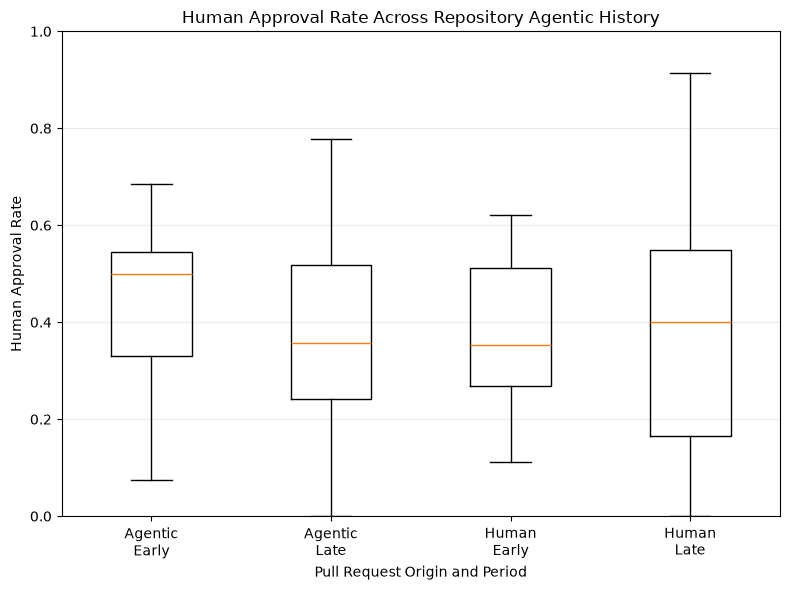

Saved figure to 
/Users/raselchowdhury/Desktop/LOG6307E/AI_Teammates_in_SE3/figures/rq2_approval_rate.png


In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))

plot_data = [
    approval_paired["Agentic_Early"],
    approval_paired["Agentic_Late"],
    approval_paired["Human_Early"],
    approval_paired["Human_Late"],
]

labels = [
    "Agentic\nEarly",
    "Agentic\nLate",
    "Human\nEarly",
    "Human\nLate",
]

ax.boxplot(
    plot_data,
    tick_labels=labels,
    showfliers=False,
)

ax.set_ylabel("Human Approval Rate")
ax.set_xlabel("Pull Request Origin and Period")

ax.set_title(
    "Human Approval Rate Across Repository Agentic History"
)

ax.set_ylim(0, 1)

ax.grid(
    axis="y",
    alpha=0.25
)

fig.tight_layout()

rq2_figure_path = (
    FIGURE_DIR
    / "rq2_approval_rate.png"
)

fig.savefig(
    rq2_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Saved figure to ")
print(rq2_figure_path)

## Sensitivity analysis

To check whether the RQ2 conclusion depends on the minimum-review threshold, we repeat the analysis using thresholds of 3, 5, and 10 reviews per cell.

In [32]:
def safe_wilcoxon(before, after):
    before = np.asarray(before, dtype=float)
    after = np.asarray(after, dtype=float)

    delta = after - before

    if len(delta) == 0 or np.allclose(delta, 0):
        return np.nan

    return wilcoxon(
        after,
        before,
        alternative="two-sided",
        zero_method="wilcox"
    ).pvalue


sensitivity_rows = []

for threshold in [3, 5, 10]:

    eligible = approval[
        approval["n_reviews"] >= threshold
    ].copy()

    wide = (
        eligible
        .pivot(
            index="repo_url",
            columns=["origin", "period"],
            values="approval_rate"
        )
    )

    required = [
        ("Agentic", "Early"),
        ("Agentic", "Late"),
        ("Human", "Early"),
        ("Human", "Late"),
    ]

    if not all(col in wide.columns for col in required):
        continue

    paired = wide[required].dropna().copy()

    paired.columns = [
        "Agentic_Early",
        "Agentic_Late",
        "Human_Early",
        "Human_Late",
    ]

    agentic_delta = (
        paired["Agentic_Late"]
        - paired["Agentic_Early"]
    )

    human_delta = (
        paired["Human_Late"]
        - paired["Human_Early"]
    )

    p_agentic = safe_wilcoxon(
        paired["Agentic_Early"],
        paired["Agentic_Late"]
    )

    p_human = safe_wilcoxon(
        paired["Human_Early"],
        paired["Human_Late"]
    )

    p_delta = safe_wilcoxon(
        human_delta,
        agentic_delta
    )

    sensitivity_rows.append({
        "min_reviews_per_cell": threshold,
        "n_repositories": len(paired),
        "median_agentic_delta": agentic_delta.median(),
        "median_human_delta": human_delta.median(),
        "p_agentic_change": p_agentic,
        "p_human_change": p_human,
        "p_difference_in_change": p_delta,
    })


sensitivity = pd.DataFrame(sensitivity_rows)

print("RQ2 sensitivity analysis: ")

display(
    sensitivity.round(4)
)

RQ2 sensitivity analysis: 


,min_reviews_per_cell,n_repositories,median_agentic_delta,median_human_delta,p_agentic_change,p_human_change,p_difference_in_change
0,3,20,-0.0074,-0.0376,0.4980,0.2954,0.6477
1,5,15,0.0485,-0.0034,0.6387,0.8904,0.8904
2,10,12,0.0665,-0.0060,0.9697,0.6221,0.5186


In [33]:
print(
    sensitivity.to_string(
        index=False
    )
)

 min_reviews_per_cell  n_repositories  median_agentic_delta  median_human_delta  p_agentic_change  p_human_change  p_difference_in_change
                    3              20             -0.007435           -0.037607          0.498009        0.295424                0.647655
                    5              15              0.048511           -0.003378          0.638672        0.890381                0.890381
                   10              12              0.066512           -0.005963          0.969727        0.622070                0.518555


In [34]:
print(
    sensitivity[
        [
            "min_reviews_per_cell",
            "n_repositories",
            "p_difference_in_change",
        ]
    ].to_string(index=False)
)

 min_reviews_per_cell  n_repositories  p_difference_in_change
                    3              20                0.647655
                    5              15                0.890381
                   10              12                0.518555


## Exporting the final data

The cleaned PR-level dataset, repository-level metrics, sensitivity results, and figures are saved for the replication package.

In [35]:
wanted_columns = [
    "id",
    "number",
    "title",
    "user",
    "agent",
    "origin",
    "state",
    "created_at",
    "closed_at",
    "merged_at",
    "repo_url",
    "period",
    "review_data_available",
    "n_human_reviews",
    "n_human_approvals",
    "has_human_review",
    "human_approval_rate",
]

available_columns = [
    col for col in wanted_columns
    if col in prs.columns
]

cleaned_pr_data = (
    prs[available_columns]
    .sort_values(
        ["repo_url", "created_at"]
    )
    .reset_index(drop=True)
)

CLEANED_PR_PATH = (
    DATA_DIR / "cleaned_pr_data.csv"
)

cleaned_pr_data.to_csv(
    CLEANED_PR_PATH,
    index=False
)

print("Saved cleaned PR dataset: ")
print(CLEANED_PR_PATH)

print("Shape: ")
print(cleaned_pr_data.shape)

print("Rows by origin and period: ")
print(
    cleaned_pr_data
    .groupby(["origin", "period"])
    .size()
)

display(cleaned_pr_data.head())

Saved cleaned PR dataset: 
/Users/raselchowdhury/Desktop/LOG6307E/AI_Teammates_in_SE3/data/cleaned_pr_data.csv
Shape: 
(6147, 17)
Rows by origin and period: 
origin   period
Agentic  Early     2044
         Late      2069
Human    Early     1128
         Late       906
dtype: int64


,id,number,title,user,agent,origin,state,created_at,closed_at,merged_at,repo_url,period,review_data_available,n_human_reviews,n_human_approvals,has_human_review,human_approval_rate
0,2756921963,603,Add LLM Integration Tests,devin-ai-integration[bot],Devin,Agentic,closed,2024-12-24 00:23:09+00:00,2025-01-09 11:13:02+00:00,NaT,https://api.github.com/repos/AgentOps-AI/agentops,Early,True,0.0,0.0,0.0,NaN
1,2760243902,605,Add integration tests for Anthropic/Cohere/Groq/Litellm/Mistral/AI21,devin-ai-integration[bot],Devin,Agentic,closed,2024-12-27 00:19:12+00:00,2024-12-29 07:52:51+00:00,2024-12-29 07:52:51+00:00,https://api.github.com/repos/AgentOps-AI/agentops,Early,True,1.0,1.0,1.0,1.0
2,2768454422,625,feat: update docs branding to match main website,devin-ai-integration[bot],Devin,Agentic,closed,2025-01-04 05:31:53+00:00,2025-01-10 19:23:55+00:00,NaT,https://api.github.com/repos/AgentOps-AI/agentops,Early,True,0.0,0.0,0.0,NaN
3,2271774186,639,upgrade version,areibman,Human,Human,closed,2025-01-11 03:17:19+00:00,2025-01-11 03:20:34+00:00,2025-01-11 03:20:34+00:00,https://api.github.com/repos/AgentOps-AI/agentops,Early,True,1.0,1.0,1.0,1.0
4,2282594982,647,Move `agentops.enums` to their respective module,teocns,Human,Human,closed,2025-01-16 19:20:51+00:00,2025-01-16 21:31:17+00:00,2025-01-16 21:31:17+00:00,https://api.github.com/repos/AgentOps-AI/agentops,Early,True,0.0,0.0,0.0,NaN


In [36]:
coverage_export = coverage[
    [
        "repo_url",
        "origin",
        "period",
        "n_prs",
        "n_reviewed",
        "review_coverage",
    ]
].copy()

approval_export = approval[
    [
        "repo_url",
        "origin",
        "period",
        "n_reviews",
        "n_approved",
        "approval_rate",
    ]
].copy()

repository_metrics = coverage_export.merge(
    approval_export,
    on=[
        "repo_url",
        "origin",
        "period",
    ],
    how="outer",
)

repository_metrics = repository_metrics.sort_values(
    [
        "repo_url",
        "origin",
        "period",
    ]
).reset_index(drop=True)

REPOSITORY_METRICS_PATH = (
    DATA_DIR / "repository_metrics.csv"
)

repository_metrics.to_csv(
    REPOSITORY_METRICS_PATH,
    index=False,
)

SENSITIVITY_PATH = (
    DATA_DIR / "rq2_sensitivity.csv"
)

sensitivity.to_csv(
    SENSITIVITY_PATH,
    index=False,
)

print("Saved repository metrics: ")
print(REPOSITORY_METRICS_PATH)

print("Shape: ")
print(repository_metrics.shape)

print("Saved RQ2 sensitivity analysis: ")
print(SENSITIVITY_PATH)

display(repository_metrics.head())

Saved repository metrics: 
/Users/raselchowdhury/Desktop/LOG6307E/AI_Teammates_in_SE3/data/repository_metrics.csv
Shape: 
(184, 9)
Saved RQ2 sensitivity analysis: 
/Users/raselchowdhury/Desktop/LOG6307E/AI_Teammates_in_SE3/data/rq2_sensitivity.csv


,repo_url,origin,period,n_prs,n_reviewed,review_coverage,n_reviews,n_approved,approval_rate
0,https://api.github.com/repos/AgentOps-AI/agentops,Agentic,Early,25,5.0,0.200000,7.0,6.0,0.857143
1,https://api.github.com/repos/AgentOps-AI/agentops,Agentic,Late,26,3.0,0.115385,4.0,2.0,0.500000
2,https://api.github.com/repos/AgentOps-AI/agentops,Human,Early,32,11.0,0.343750,26.0,11.0,0.423077
3,https://api.github.com/repos/AgentOps-AI/agentops,Human,Late,1,1.0,1.000000,1.0,1.0,1.000000
4,https://api.github.com/repos/EricLBuehler/mistral.rs,Agentic,Early,13,0.0,0.000000,NaN,NaN,NaN


## Final summary

The final cell collects the main sample sizes, descriptive statistics, statistical-test results, and generated files used in the report.

In [37]:
def get_pvalue(result):
    if result is None:
        return np.nan
    return float(result.pvalue)


print("=" * 70)
print("FINAL STUDY SUMMARY")
print("=" * 70)

print("DATASET")
print("-" * 70)

print("AIDev revision: ", REVISION)
print("Final repositories: ", prs["repo_url"].nunique())
print("Final PRs:", len(prs))

print("PR distribution: ")
print(
    prs.groupby(["origin", "period"])
    .size()
)

print("Human review events: ")
print(
    "Agentic PRs: ",
    len(agentic_human_reviews)
)
print(
    "Human PRs: ",
    len(human_human_reviews)
)


print("\n" + "=" * 70)
print("RQ1 — HUMAN REVIEW COVERAGE")
print("=" * 70)

print("Paired repositories: ", len(coverage_paired))

print("Median repository-level coverage: ")
print(
    "Agentic Early: ",
    round(coverage_paired["Agentic_Early"].median(), 4)
)
print(
    "Agentic Late: ",
    round(coverage_paired["Agentic_Late"].median(), 4)
)
print(
    "Human Early: ",
    round(coverage_paired["Human_Early"].median(), 4)
)
print(
    "Human Late:",
    round(coverage_paired["Human_Late"].median(), 4)
)

print("\nMedian Early → Late change: ")
print(
    "Agentic: ",
    round(coverage_paired["Agentic_Delta"].median(), 4)
)
print(
    "Human:",
    round(coverage_paired["Human_Delta"].median(), 4)
)

print("Wilcoxon p-values: ")
print(
    "Agentic Early vs Late: ",
    round(get_pvalue(rq1_agentic_test), 4)
)
print(
    "Human Early vs Late: ",
    round(get_pvalue(rq1_human_test), 4)
)
print(
    "Difference in trajectories: ",
    round(get_pvalue(rq1_delta_test), 4)
)


print("\n" + "=" * 70)
print("RQ2 — HUMAN APPROVAL RATE")
print("=" * 70)

print(
    "Minimum reviews per cell: ",
    MIN_REVIEWS_PER_CELL
)

print(
    "Paired repositories:",
    len(approval_paired)
)

print("Median repository-level approval rates: ")
print(
    "Agentic Early: ",
    round(approval_paired["Agentic_Early"].median(), 4)
)
print(
    "Agentic Late: ",
    round(approval_paired["Agentic_Late"].median(), 4)
)
print(
    "Human Early:",
    round(approval_paired["Human_Early"].median(), 4)
)
print(
    "Human Late: ",
    round(approval_paired["Human_Late"].median(), 4)
)

print("Median Early => Late change: ")
print(
    "Agentic: ",
    round(approval_paired["Agentic_Delta"].median(), 4)
)
print(
    "Human: ",
    round(approval_paired["Human_Delta"].median(), 4)
)

print("Wilcoxon p-values: ")
print(
    "Agentic Early vs Late: ",
    round(get_pvalue(rq2_agentic_test), 4)
)
print(
    "Human Early vs Late: ",
    round(get_pvalue(rq2_human_test), 4)
)
print(
    "Difference in trajectories: ",
    round(get_pvalue(rq2_delta_test), 4)
)


print("\n" + "=" * 70)
print("OUTPUT FILES")
print("=" * 70)

print("Cleaned PR dataset: ")
print(CLEANED_PR_PATH)

print("Repository metrics: ")
print(REPOSITORY_METRICS_PATH)

print("RQ2 sensitivity: ")
print(SENSITIVITY_PATH)

print("RQ1 figure: ")
print(rq1_figure_path)

print("RQ2 figure: ")
print(rq2_figure_path)

FINAL STUDY SUMMARY
DATASET
----------------------------------------------------------------------
AIDev revision:  68ed5f4b
Final repositories:  46
Final PRs: 6147
PR distribution: 
origin   period
Agentic  Early     2044
         Late      2069
Human    Early     1128
         Late       906
dtype: int64
Human review events: 
Agentic PRs:  3922
Human PRs:  2734

RQ1 — HUMAN REVIEW COVERAGE
Paired repositories:  46
Median repository-level coverage: 
Agentic Early:  0.2247
Agentic Late:  0.2424
Human Early:  0.3594
Human Late: 0.5109

Median Early → Late change: 
Agentic:  -0.0045
Human: 0.0191
Wilcoxon p-values: 
Agentic Early vs Late:  0.3883
Human Early vs Late:  0.1968
Difference in trajectories:  0.1667

RQ2 — HUMAN APPROVAL RATE
Minimum reviews per cell:  5
Paired repositories: 15
Median repository-level approval rates: 
Agentic Early:  0.5
Agentic Late:  0.3564
Human Early: 0.3529
Human Late:  0.4012
Median Early => Late change: 
Agentic:  0.0485
Human:  -0.0034
Wilcoxon p-value